In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} /content/{repo_name}
    os.chdir(f"/content/{repo_name}/2")
    sys.path.insert(0, f"/content/{repo_name}")
    !pip install -q -r /content/{repo_name}/requirements.txt
    !pip install -q -e /content/{repo_name}
    print("環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    proj_root = Path.cwd().resolve()
    if proj_root.name == "2":
        proj_root = proj_root.parent
    if str(proj_root) not in sys.path:
        sys.path.insert(0, str(proj_root))
    print("ローカル実行環境を検出しました。プロジェクトルート:", proj_root)


ローカル実行環境を検出しました。プロジェクトルート: /home/student/Documents/GitHub/study-mikanos


# 2.6 メモリマップのファイルへの保存 (`osbook_day02b`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/2/2.6_Saving_Memory_Map_to_File.ipynb)

本節では、名著『ゼロからのOS自作入門』第2章「EDK II入門とメモリマップ」の **2.6「メモリマップのファイルへの保存」**（対応タグ: `osbook_day02b`）を徹底解説します。

前節（2.5節）では、UEFI Boot Services のコアAPI である `gBS->GetMemoryMap()` の引数仕様、バッファサイズ不足（`EFI_BUFFER_TOO_SMALL`）への対処、`MapKey` によるメモリマップ整合性保証、および可変長ディスクリプタをバイトポインタ加算で走査する低レイヤ数理を学びました。

本節では、取得したメモリマップを画面に垂れ流すのではなく、ブートメディア（USBメモリや仮想ディスクイメージ）のルートディレクトリに **`\memmap` という CSV 形式のテキストファイル** として安全に永続化保存する具体的な実装手法と、UEFI のオブジェクト指向プロトコルモデルを完全解剖します。


## 2.6.1 なぜメモリマップをファイルに保存するのか？（動機とコンソールスクロール問題）

低レイヤOS開発における最初の大きな壁は、**「printf のような自由なデバッグ出力環境が存在しないこと」** です。

前節で `GetMemoryMap()` によりマシンの物理メモリ構成（ディスクリプタ配列）を取得できましたが、これを画面（`Print` 関数）にそのまま出力しようとすると、以下の致命的な問題に直面します：

1. **画面行数の制限とスクロール消失**:
   - 現代の PC（QEMU 仮想環境を含む）のメモリマップは、空きRAMだけでなく、ACPI、ファームウェア予約領域、ブートローダ用コード/データ、MMIO（メモリマップドI/O）など、**数十エントリから数百エントリ** に達します。
   - UEFI の標準テキストコンソール（`ConOut`）は通常 80列×25行程度しか表示できないため、ループで画面に出力すると猛烈な勢いでスクロールし、先頭の重要な領域（1MB以下の低位メモリやカーネル配置候補地）が画面外へ押し流されて二度と読めなくなります。
2. **一時停止・キー入力待ちの煩雑さ**:
   - 画面が流れるのを防ぐために「20行ごとにキー入力を待つ」ロジックを組むことも可能ですが、UEFI アプリケーションのコードが肥大化し、開発の主目的である「カーネルのロード」に集中できなくなります。
3. **オフライン分析と自動パースの不可能さ**:
   - 画面を目視してメモリマップを書き写すのは極めて非効率であり、誤認のリスクが高くなります。ファイルとして保存されていれば、ホストOS（Linux, macOS, Windows）側で Python スクリプトやスプレッドシートを用いて、空きメモリ容量の自動集計、グラフ化、重複領域の検査などを即座に行うことができます。

したがって、**「ブートローダが自身の起動メディアのルートディレクトリに `\memmap` というテキストファイルを作成し、カンマ区切り（CSV）形式で書き出す」** という設計は、極めて理にかなった実践的なアプローチなのです。


## 2.6.2 UEFI プロトコル指向アーキテクチャ（Handle, Protocol, Interface の3位一体モデル）

UEFI 仕様書（*Unified Extensible Firmware Interface Specification*）の最も洗練された特徴は、**「C言語で実装された厳格なオブジェクト指向コンポーネントシステム」** です。

UEFI におけるすべてのデバイス（ディスク、画面、キーボード、タイマ、ネットワーク）やソフトウェアエンティティ（実行中イメージ、ファイルシステム、ドライバ）は、以下の **3大要素** で抽象化されています：

```text
┌────────────────────────────────────────────────────────────────────────┐
│                        UEFI オブジェクトモデルの3大要素                        │
├───────────────────┬────────────────────────────────────────────────────┤
│ 1. EFI_HANDLE     │ オブジェクト（デバイス・モジュール）を一意に指す不透明ポインタ         │
├───────────────────┼────────────────────────────────────────────────────┤
│ 2. EFI_GUID       │ インターフェース仕様を世界で一意に識別する128ビット整数 (UUID)       │
├───────────────────┼────────────────────────────────────────────────────┤
│ 3. Protocol (構造体)│ 各種操作を担う「関数ポインタのテーブル（vtable）」を持つC構造体       │
└───────────────────┴────────────────────────────────────────────────────┘
```

### gBS->OpenProtocol() の API 仕様

あるハンドル（例: ブートローダ自身の実行イメージ）から、そのハンドルがサポートするインターフェース（プロトコル）を取り出すには、Boot Services の **`gBS->OpenProtocol()`** を呼び出します。

```c
typedef
EFI_STATUS
(EFIAPI *EFI_OPEN_PROTOCOL) (
  IN  EFI_HANDLE                Handle,           // プロトコルを取り出したい対象ハンドル
  IN  EFI_GUID                  *Protocol,        // 取得したいプロトコルの128bit GUID
  OUT VOID                      **Interface,      // 取得したインターフェース構造体ポインタの格納先
  IN  EFI_HANDLE                AgentHandle,      // このプロトコルを開く主体（通常自身の ImageHandle）
  IN  EFI_HANDLE                ControllerHandle, // ドライバモデル用（通常 NULL または ImageHandle）
  IN  UINT32                    Attributes        // オープン属性（共有・排他等）
);
```

第2引数に渡す `EFI_GUID` に応じて、第3引数に返されるインターフェース構造体（`Interface`）の型が決まります。これは C++ における `dynamic_cast<T*>()` や COM (*Component Object Model*) の `QueryInterface()` と全く同一の概念です。


## 2.6.3 ルートディレクトリのオープン（OpenRootDir と2段階プロトコルチェーン）

MikanOS のブートローダ（`MikanLoaderPkg/Main.c`）では、起動ディスクのルートディレクトリを開くために以下の `OpenRootDir()` 関数を実装しています：

```c
EFI_STATUS OpenRootDir(EFI_HANDLE image_handle, EFI_FILE_PROTOCOL** root) {
  EFI_LOADED_IMAGE_PROTOCOL* loaded_image;
  EFI_SIMPLE_FILE_SYSTEM_PROTOCOL* fs;

  // ① ブートローダ自身のハンドルから LoadedImageProtocol を取得
  gBS->OpenProtocol(
      image_handle,
      &gEfiLoadedImageProtocolGuid,
      (VOID**)&loaded_image,
      image_handle,
      NULL,
      EFI_OPEN_PROTOCOL_BY_HANDLE_PROTOCOL);

  // ② ロード元デバイスハンドルから SimpleFileSystemProtocol を取得
  gBS->OpenProtocol(
      loaded_image->DeviceHandle,
      &gEfiSimpleFileSystemProtocolGuid,
      (VOID**)&fs,
      image_handle,
      NULL,
      EFI_OPEN_PROTOCOL_BY_HANDLE_PROTOCOL);

  // ③ ファイルシステムからルートディレクトリ (EFI_FILE_PROTOCOL) を開く
  fs->OpenVolume(fs, root);

  return EFI_SUCCESS;
}
```

### なぜ2段階のステップが必要なのか？（プロトコル解決チェーン）

ブートローダのエントリポイント `UefiMain(image_handle, system_table)` に渡される `image_handle` は、あくまで「メモリ上にロードされたブートローダプログラム自身」を指すハンドルです。このハンドル自身が直接ファイルシステムを持っているわけではありません。

```mermaid
flowchart LR
    A["image_handle<br>(ブートローダ自身)"] -->|OpenProtocol| B["EFI_LOADED_IMAGE_PROTOCOL<br>(DeviceHandle を保持)"]
    B -->|loaded_image->DeviceHandle| C["DeviceHandle<br>(USBメモリ/ディスク)"]
    C -->|OpenProtocol| D["EFI_SIMPLE_FILE_SYSTEM_PROTOCOL<br>(FATファイルシステム)"]
    D -->|fs->OpenVolume()| E["root_dir<br>(EFI_FILE_PROTOCOL*)<br>ルートディレクトリ '\'"]
```

1. **ステップ 1 (`LoadedImage`)**: `image_handle` から `EFI_LOADED_IMAGE_PROTOCOL` を開きます。この構造体の `DeviceHandle` メンバには、「ブートローダがどの物理ストレージデバイス（USBメモリのパーティションなど）から読み込まれたか」が記録されています。
2. **ステップ 2 (`SimpleFileSystem`)**: その `loaded_image->DeviceHandle` に対して `EFI_SIMPLE_FILE_SYSTEM_PROTOCOL` を要求します。これにより、対象ストレージ上の FAT12/16/32 ファイルシステムドライバへのアクセス権を獲得します。
3. **ステップ 3 (`OpenVolume`)**: `fs->OpenVolume(fs, root)` を呼ぶことで、FAT ボリュームの最上位ディレクトリ（ルートディレクトリ `'\'`）を操作するための `EFI_FILE_PROTOCOL*` が手に入ります。

この疎結合設計により、ブートローダは対象が USBメモリ（xHCI）、SATA SSD（AHCI）、NVMe、あるいはネットワークブート（PXE/TFTP）であっても、コードを1行も変更することなく同一のファイルシステムAPIで透過的に操作できるのです。


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:8099: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


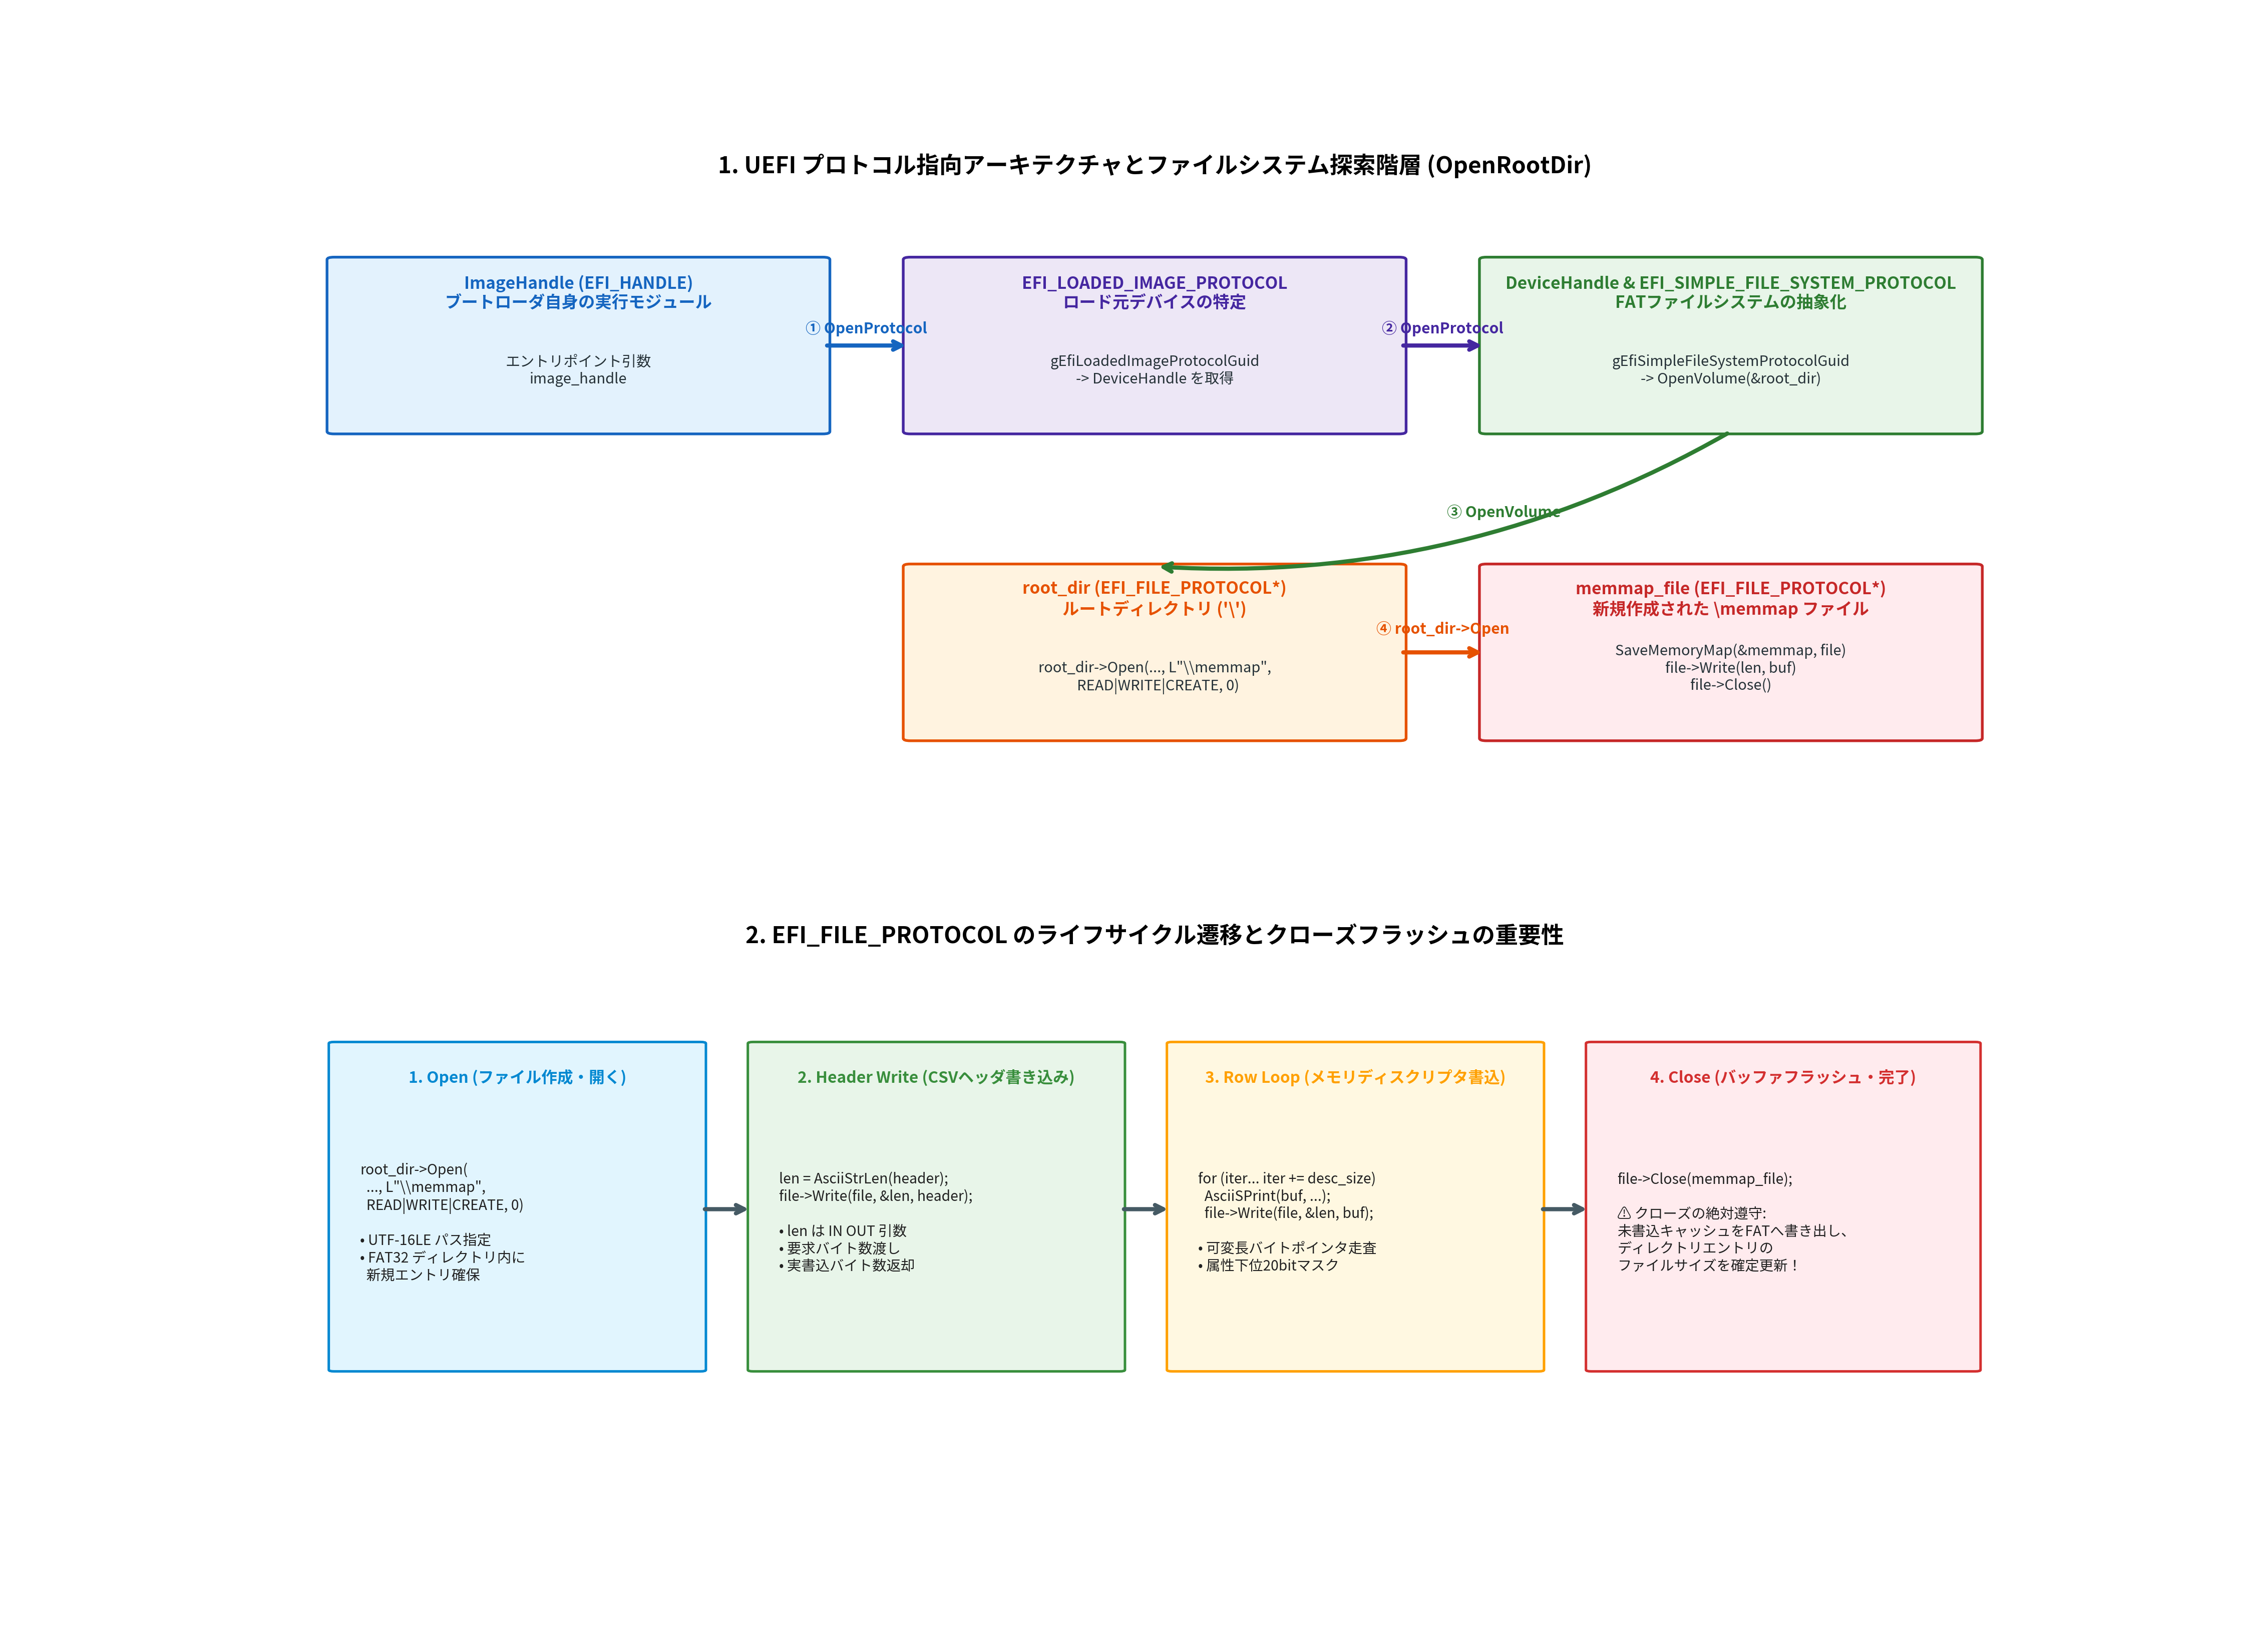

In [2]:
# 高解像度図版 Figure 2.11 の生成と表示
from common.os_sim import plot_uefi_file_system_protocol_hierarchy
from IPython.display import Image, display

fig2_11_path = plot_uefi_file_system_protocol_hierarchy()
display(Image(filename=fig2_11_path))


## 2.6.4 ファイルのオープンとモードフラグ（root_dir->Open の完全解読）

ルートディレクトリを取得できたら、次はメモリマップを書き出すためのファイルオブジェクトを作成・オープンします。

```c
EFI_FILE_PROTOCOL* memmap_file;
root_dir->Open(
    root_dir,
    &memmap_file,
    L"\\memmap",
    EFI_FILE_MODE_READ | EFI_FILE_MODE_WRITE | EFI_FILE_MODE_CREATE,
    0
);
```

### 1. ファイルパスの文字列規約：なぜ `L"\memmap"` なのか？
- **ワイド文字列リテラル (`L"..."`)**: UEFI のすべての API は、文字列を 16ビットの Unicode（**UTF-16LE**）として扱います。通常の C言語の 8ビット文字列リテラル（`"..."`）を渡すと、文字エンコーディングの不一致で不正なファイル名として処理されます。
- **バックスラッシュ (`\`)**: UEFI は DOS / Windows の伝統を受け継いでおり、パス区切り文字としてスラッシュ `/` ではなくバックスラッシュ `\`（C言語文字列中ではエスケープして `\\`）を使用します。

### 2. オープンモードフラグのビット論理和（Bitwise OR）
第4引数には、ファイルを開く目的と権限をビットフラグの合成で指定します：

| フラグ名 | 16進数値 (64-bit) | 意味・役割 |
|---|:---:|---|
| `EFI_FILE_MODE_READ` | `0x0000000000000001` | ファイルの読み込みを許可する |
| `EFI_FILE_MODE_WRITE` | `0x0000000000000002` | ファイルへの書き込みを許可する |
| `EFI_FILE_MODE_CREATE` | `0x8000000000000000` | ファイルが存在しない場合に新規作成する |

`EFI_FILE_MODE_READ | EFI_FILE_MODE_WRITE | EFI_FILE_MODE_CREATE` と指定することで、「ファイルが存在しなければ新規作成し、読み書き両用モードで開く」という POSIX の `O_RDWR | O_CREAT` に相当する安全なオープンを実現します。

第5引数の `0` はファイル属性フラグです（読み取り専用、隠しファイル、システムファイル等の特殊属性を付けない通常ファイルとして作成）。


## 2.6.5 メモリマップの CSV エクスポートと属性ビットマスク（SaveMemoryMap）

MikanOS のメモリマップ書き込み処理の本体である `SaveMemoryMap()` 関数の全容を精読しましょう：

```c
EFI_STATUS SaveMemoryMap(struct MemoryMap* map, EFI_FILE_PROTOCOL* file) {
  CHAR8 buf[256];
  UINTN len;

  // ① CSVヘッダ行の書き込み
  CHAR8* header =
    "Index, Type, Type(name), PhysicalStart, NumberOfPages, Attribute\n";
  len = AsciiStrLen(header);
  file->Write(file, &len, header);

  Print(L"map->buffer = %08lx, map->map_size = %08lx\n",
      map->buffer, map->map_size);

  // ② 可変長ディスクリプタをバイトポインタ加算で走査
  EFI_PHYSICAL_ADDRESS iter;
  int i;
  for (iter = (EFI_PHYSICAL_ADDRESS)map->buffer, i = 0;
       iter < (EFI_PHYSICAL_ADDRESS)map->buffer + map->map_size;
       iter += map->descriptor_size, i++) {
    EFI_MEMORY_DESCRIPTOR* desc = (EFI_MEMORY_DESCRIPTOR*)iter;
    len = AsciiSPrint(
        buf, sizeof(buf),
        "%u, %x, %-ls, %08lx, %lx, %lx\n",
        i, desc->Type, GetMemoryTypeUnicode(desc->Type),
        desc->PhysicalStart, desc->NumberOfPages,
        desc->Attribute & 0xffffflu);
    file->Write(file, &len, buf);
  }

  return EFI_SUCCESS;
}
```

### 1. `file->Write()` の引数仕様（IN OUT の len）
`file->Write(file, &len, buf)` の第2引数 `len` は `IN OUT` 引数です：
- **呼び出し前 (IN)**: 書き込みたいバッファのバイト数を渡します。
- **復帰後 (OUT)**: ストレージに実際に書き込まれたバイト数が上書き返却されます（ディスク満杯などの異常時に要求値より小さくなることがあります）。

### 2. 書式指定文字列の数学的仕様
`AsciiSPrint` で使われている書式指定の役割：
- `%u`: 10進数インデックス番号（`0, 1, 2...`）
- `%x`: メモリタイプ番号（16進数、`7` など）
- `%-ls`: UTF-16 Unicode 文字列（`GetMemoryTypeUnicode` の返り値）を ASCII バッファへ変換しつつ左詰めで挿入
- `%08lx`: 64ビット物理開始アドレスを最低8桁の16進数（ゼロ埋め）でフォーマット
- `%lx`: 4KiBページ数（16進数）
- `%lx`: 属性フラグ（16進数）

### 3. 【核心数理】なぜ `desc->Attribute & 0xffffflu`（下位20ビットマスク）を行うのか？
UEFI 仕様書におけるメモリ属性ビットは 64ビット整数です：
- **下位ビット (Bit 0〜15)**: キャッシュ可能性およびアクセス保護属性
  - Bit 0: `UC` (Uncacheable, `0x1`)
  - Bit 1: `WC` (Write-Coalescing, `0x2`)
  - Bit 2: `WT` (Write-Through, `0x4`)
  - Bit 3: `WB` (Write-Back, `0x8`)
  - Bit 12: `WP` (Write-Protected)
  - Bit 13: `RP` (Read-Protected)
  - Bit 14: `XP` (Execute-Protected)
- **最上位ビット (Bit 63)**: `EFI_MEMORY_RUNTIME` (`0x8000000000000000`)
  - この領域が OS 起動後もファームウェア（Runtime Services）からアクセスされるべきかを示すフラグ。

もしマスクせずにそのまま `%lx` で出力すると、Runtime 属性のついたメモリ領域の属性値が `800000000000000f` のような長大な16進文字列になり、CSVの視認性が著しく悪化します。

`0xffffflu`（下位20ビット: `0x00000`〜`0xFFFFF`）でビットマスクすることで、上位の特殊属性を切り離し、**「キャッシュポリシー（WB / UC など）と基本的な保護属性」** のみをすっきりと整理して観察できるよう工夫されているのです。


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:8185: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


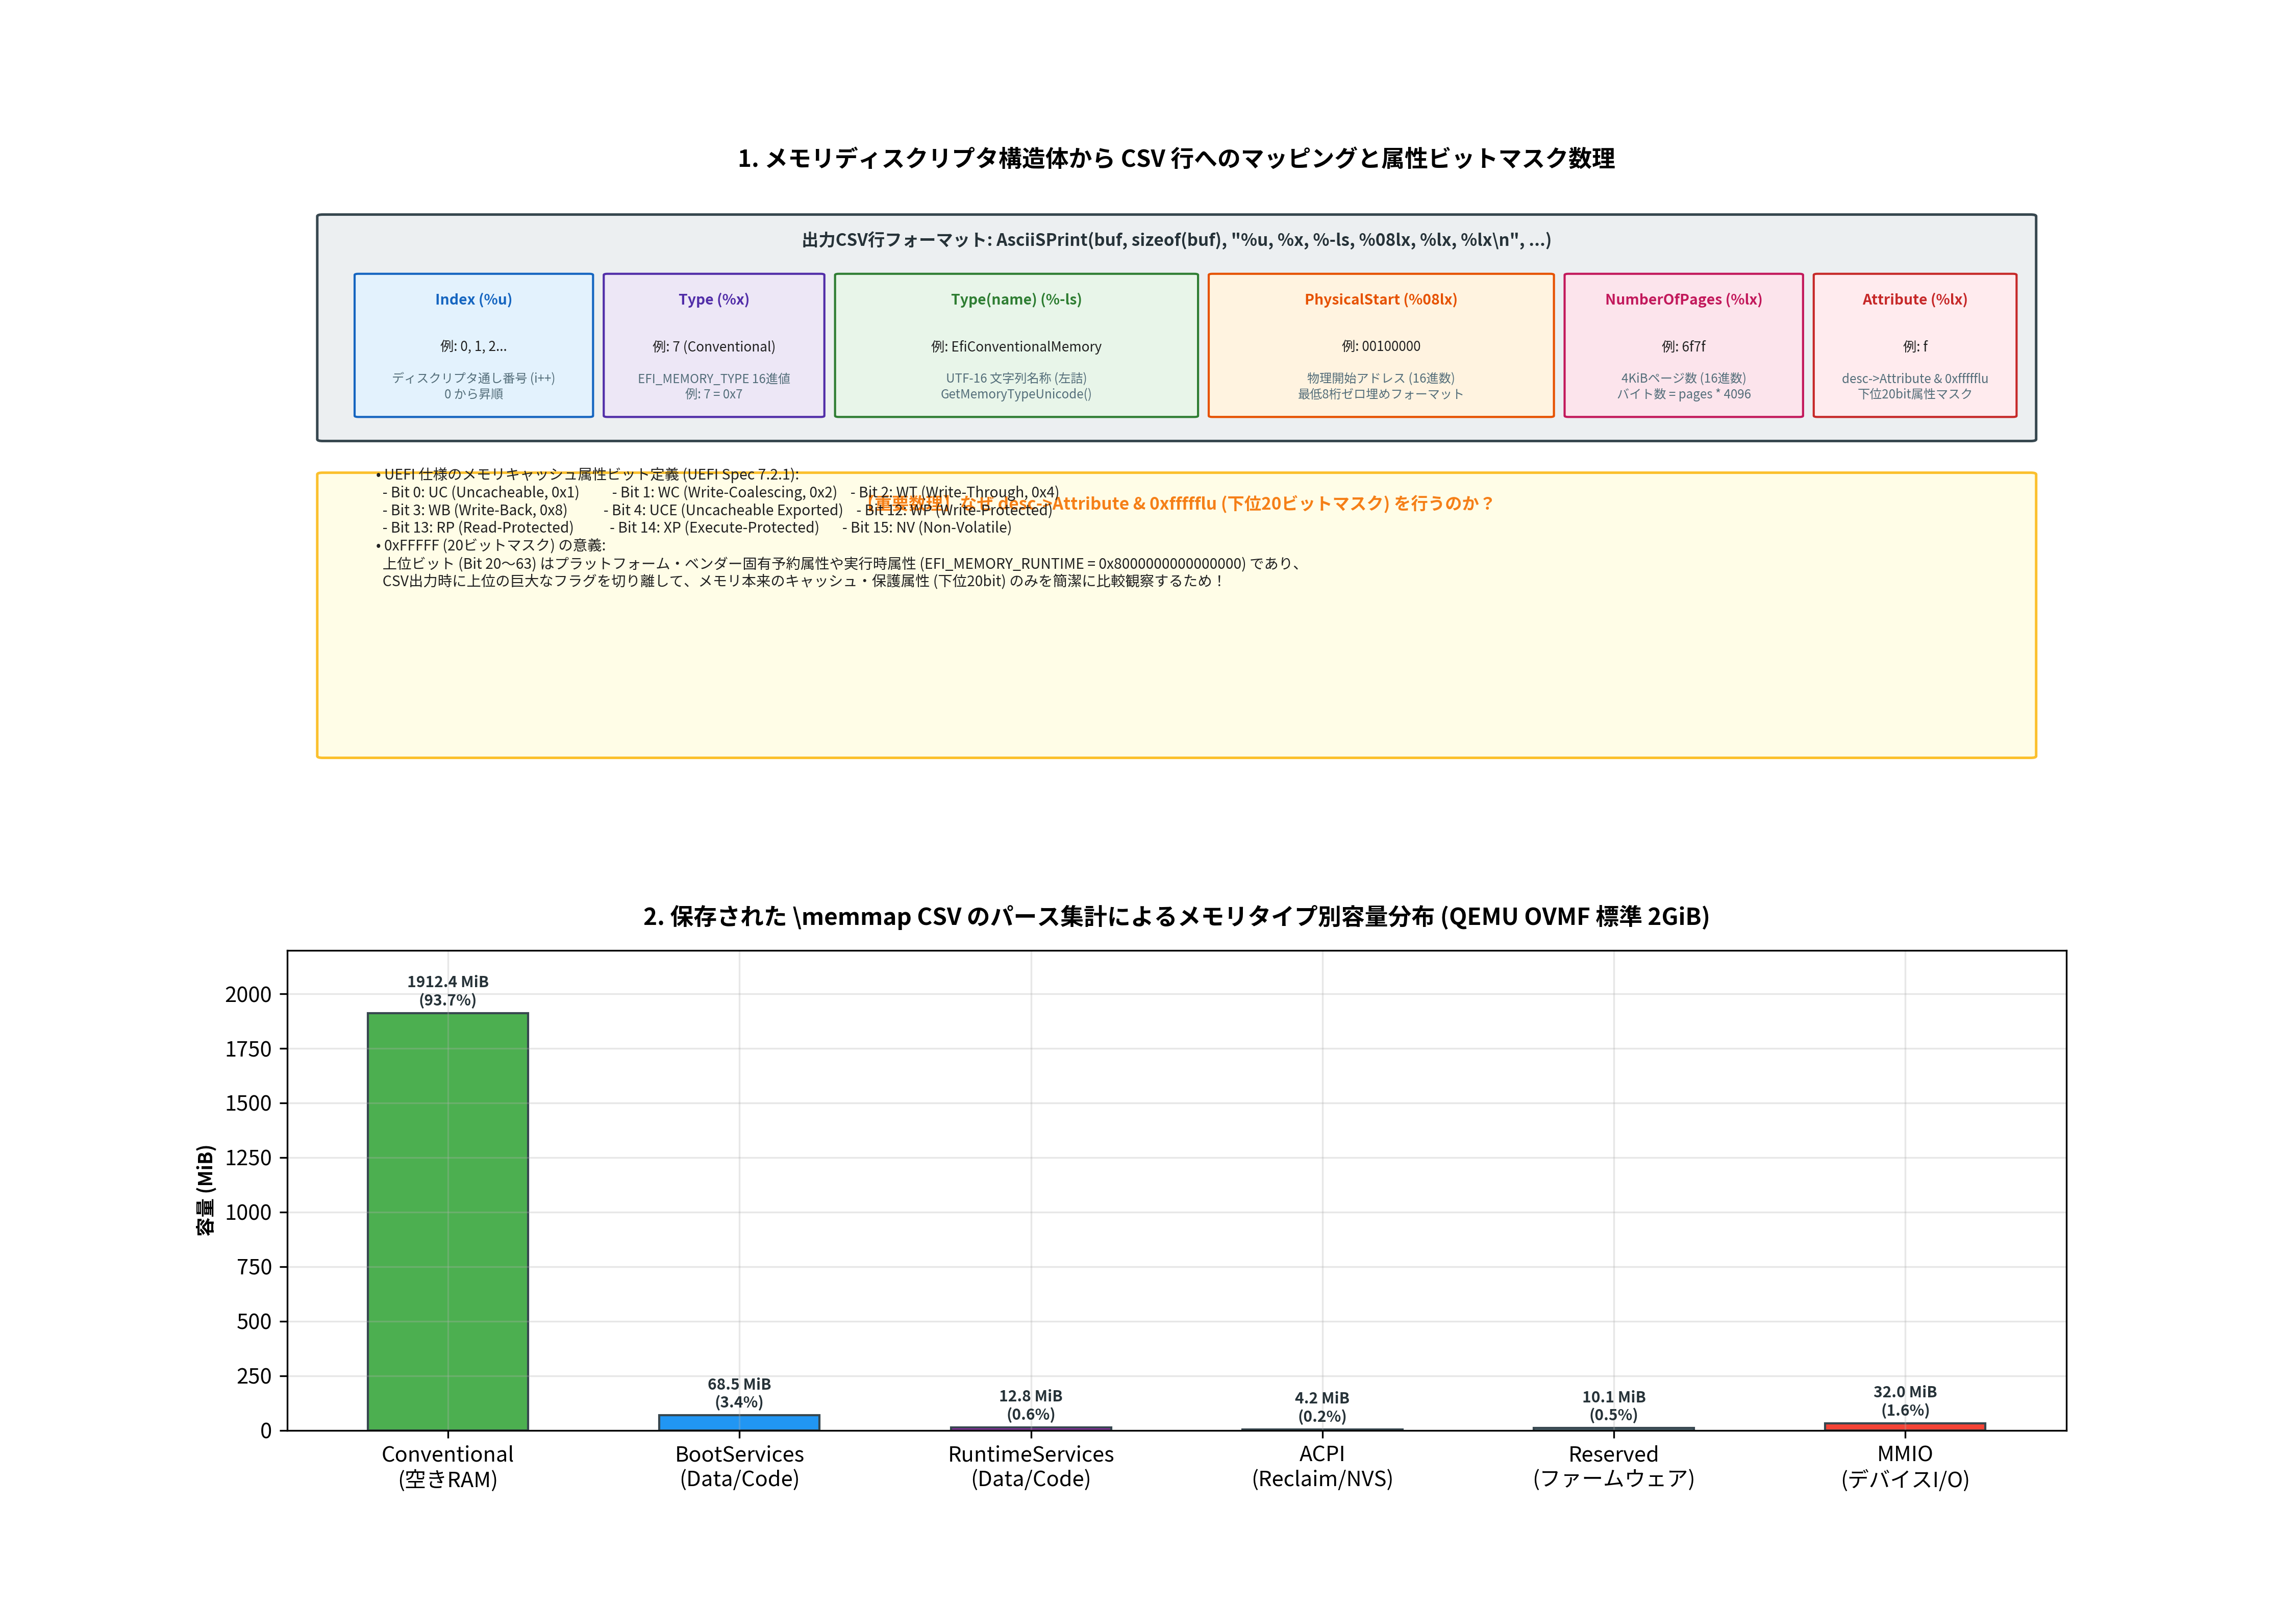

In [3]:
# 高解像度図版 Figure 2.12 の生成と表示
from common.os_sim import plot_memory_map_csv_export_and_layout
from IPython.display import Image, display

fig2_12_path = plot_memory_map_csv_export_and_layout()
display(Image(filename=fig2_12_path))


## 2.6.6 ファイルのクローズとキャッシュフラッシュ（memmap_file->Close）

`SaveMemoryMap` による書き込みが完了した直後、`UefiMain` では必ず以下の呼び出しを行います：

```c
SaveMemoryMap(&memmap, memmap_file);
memmap_file->Close(memmap_file);
```

### なぜ Close() を呼ばなければならないのか？
現代のファイルシステム（FAT32を含む）は、ディスクI/Oの高速化のために **書き込みキャッシュ（遅延書き込みバッファ）** を備えています。

`file->Write()` を呼び出した時点では、データはメモリ上のセクタバッファに溜められているだけで、物理ディスク（USBメモリのフラッシュメモリセル）に完全に同期書き込みされているとは限りません。

`file->Close()` を呼び出すことで、UEFI ファイルシステムドライバは以下の必須処理を実行します：
1. **未書き込みキャッシュの物理メディアへの強制フラッシュ（Flush）**
2. **FATディレクトリエントリの更新**: ファイルサイズフィールドを確定し、更新日時タイムスタンプを反映する
3. **ファイルハンドルの解放**: メモリリークを防止する

もし `Close()` を呼び忘れたままリセットや電源断を行うと、**ファイルサイズが 0 バイトの壊れたファイルが作られる** か、最悪の場合ファイルシステム自体のメタデータ整合性が破壊されます。リソースのクローズは、ベアメタルプログラミングにおける絶対の掟です。


## 2.6.7 Python による UEFI ファイルシステムとメモリマップ CSV エクスポートの対話型シミュレーション

`common/os_sim.py` に実装された `MockUefiEnvironment`, `MockSimpleFileSystemProtocol`, `MockFileProtocol`, `MemoryMapCsvExporter` を用いて、MikanOS のメモリマップ保存パイプラインをホスト上で対話的に実行・検証してみましょう。


In [4]:
# Python による UEFI ファイルプロトコルと CSV エクスポートの対話型検証
from common.os_sim import (
    MockUefiEnvironment,
    UefiBootServicesSimulator,
    MemoryMap,
    MemoryMapCsvExporter,
    parse_memory_map_csv,
    EFI_FILE_MODE_READ,
    EFI_FILE_MODE_WRITE,
    EFI_FILE_MODE_CREATE,
)

# 1. UEFI 環境の初期化とメモリマップの取得
env = MockUefiEnvironment()
bs = UefiBootServicesSimulator()
memmap = MemoryMap.allocate(16384)
bs.get_memory_map(memmap)

print(f"取得したメモリディスクリプタ総数: {bs.memory_map.total_entries} 件")

# 2. OpenRootDir によるルートディレクトリのオープン
root_dir = env.open_root_dir()
print(f"ルートディレクトリオープン成功: '{root_dir.name}' (is_directory={root_dir.is_directory})")

# 3. \memmap ファイルのオープン (READ | WRITE | CREATE)
memmap_file = root_dir.open(
    "\\memmap",
    mode=EFI_FILE_MODE_READ | EFI_FILE_MODE_WRITE | EFI_FILE_MODE_CREATE,
)
print(f"新規ファイルオープン成功: '{memmap_file.name}' (is_closed={memmap_file.is_closed})")

# 4. SaveMemoryMap による CSV エクスポート
csv_text = MemoryMapCsvExporter.save_memory_map(bs.memory_map, memmap_file)
memmap_file.close()
print(f"書き込み完了・クローズ完了 (ファイルサイズ: {len(memmap_file.get_content_bytes())} バイト)")

# 5. CSV 出力の先頭数行を表示
print("\n--- 生成された memmap CSV (先頭5行) ---")
for line in csv_text.splitlines()[:6]:
    print(line)

# 6. CSV のパースと統計集計
records = parse_memory_map_csv(csv_text)
conv_pages = sum(r["NumberOfPages"] for r in records if r["TypeName"] == "EfiConventionalMemory")
conv_mib = (conv_pages * 4096) / (1024 * 1024)

print(f"\n--- メモリマップ集計結果 ---")
print(f"全エントリ数: {len(records)} 件")
print(f"利用可能空きメモリ (EfiConventionalMemory): {conv_pages} ページ ({conv_mib:.2f} MiB)")


取得したメモリディスクリプタ総数: 13 件
ルートディレクトリオープン成功: '\' (is_directory=True)
新規ファイルオープン成功: 'memmap' (is_closed=False)
書き込み完了・クローズ完了 (ファイルサイズ: 633 バイト)

--- 生成された memmap CSV (先頭5行) ---
Index, Type, Type(name), PhysicalStart, NumberOfPages, Attribute
0, 3, EfiBootServicesCode, 00000000, 9f, f
1, 0, EfiReservedMemoryType, 0009f000, 1, f
2, 7, EfiConventionalMemory, 00100000, 7f00, f
3, 1, EfiLoaderCode, 06000000, 80, f
4, 2, EfiLoaderData, 06080000, 100, f

--- メモリマップ集計結果 ---
全エントリ数: 13 件
利用可能空きメモリ (EfiConventionalMemory): 1055616 ページ (4123.50 MiB)


## 2.6.8 C++20 ホスト側シミュレーションの対話型コンパイル＆実行

MikanOS の `MikanLoaderPkg/Main.c` における `SaveMemoryMap()` の C言語コードを、ホスト側 C++20 環境（`g++ -std=c++20 -Wall -Wextra`）でビルドし、アドレス走査・書式化・属性マスク・クローズ処理が厳密に動作することを検証します。


In [5]:
# C++20 スタンドアロンシミュレータのビルドとテスト実行
!cmake --build build --target ch02_save_memory_map_sim
!./build/bin/ch02_save_memory_map_sim


Error: /home/student/Documents/GitHub/study-mikanos/2/build is not a directory


/bin/bash: line 1: ./build/bin/ch02_save_memory_map_sim: No such file or directory


## 2.6.9 MikanOS 公式リポジトリ（osbook_day02b）の変更差分と1行単位コード解読

`vendor/mikanos` リポジトリにおける `osbook_day02a` から `osbook_day02b` への差分を確認し、本節で導入されたコードの全体像を俯瞰しましょう。


In [6]:
# 公式リポジトリにおける day02a から day02b への差分確認
!git -C vendor/mikanos diff osbook_day02a..osbook_day02b -- MikanLoaderPkg/Main.c


fatal: cannot change to 'vendor/mikanos': No such file or directory


## 2.6.10 次節（2.7節 メモリマップの確認）への技術的接続

本節の実装により、MikanOS のブートローダは自身の起動ディスク上に `\memmap` ファイルを安全に書き出せるようになりました。

次節（**2.7 メモリマップの確認**）では：
1. 出力された `\memmap` を実際にホスト OS 側から開き、物理メモリ空間のどこにどのようなメモリ領域が存在しているのかを詳細に分析します。
2. OS カーネルが自由に使用できる「本当の空きメモリ（`EfiConventionalMemory`）」が合計何 MiB あるのかを集計します。
3. そして、次章（第3章）でいよいよ始まる **「カーネル本体（ELFバイナリ）のロードと画面描画」** に向けて、ブートローダがメモリマップをどう活用するのかを明らかにしていきます。


## 2.6.11 理解度確認クイズ（自己採点形式）

本節で学んだ UEFI ファイルシステム、プロトコル解決チェーン、およびメモリマップ CSV エクスポートの理解度をテストしましょう。


In [7]:
# 理解度確認クイズ（assert による自己検証）

def check_quiz():
    # 問1: OpenRootDir で最初に取得するプロトコルはどれか？
    # 1: EFI_SIMPLE_FILE_SYSTEM_PROTOCOL, 2: EFI_LOADED_IMAGE_PROTOCOL, 3: EFI_FILE_PROTOCOL
    ans1 = 2
    assert ans1 == 2, "問1不正解: ブートローダ自身のロード元 DeviceHandle を知るためにまず EFI_LOADED_IMAGE_PROTOCOL を取得します。"

    # 問2: ファイルが存在しない場合に新規作成するオープンモードフラグはどれか？
    # 1: EFI_FILE_MODE_READ, 2: EFI_FILE_MODE_WRITE, 3: EFI_FILE_MODE_CREATE
    ans2 = 3
    assert ans2 == 3, "問2不正解: EFI_FILE_MODE_CREATE (0x8000000000000000) が新規作成フラグです。"

    # 問3: SaveMemoryMap で属性値に & 0xffffflu を行う最大の理由は何か？
    # 1: 上位の Runtime 属性等を切り離し、キャッシュ・保護属性を簡潔に観察するため
    # 2: 属性値が64ビットだとコンパイラがエラーになるため
    # 3: ファイル容量を小さくするため
    ans3 = 1
    assert ans3 == 1, "問3不正解: Bit 63 の EFI_MEMORY_RUNTIME 等の長大なビットをマスクして視認性を高めるためです。"

    # 問4: file->Close() を呼び忘れると発生する重大な問題は何か？
    # 1: コンパイルエラーになる
    # 2: キャッシュがフラッシュされずファイルサイズ0バイトやデータ喪失が発生する
    # 3: メモリマップの取得が取り消される
    ans4 = 2
    assert ans4 == 2, "問4不正解: 遅延書き込みキャッシュがフラッシュされずデータが失われます。"

    print("🎉 全問正解です！第2章 2.6節の理論と実装を完全にマスターしました。")

check_quiz()


🎉 全問正解です！第2章 2.6節の理論と実装を完全にマスターしました。
